# Data Preparation - `vita_sign.csv`

In [1]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict
from sklearn.preprocessing import MinMaxScaler


from scipy.stats import pearsonr


In [2]:
# Loading Datasets
vital_sign_df = pd.read_csv('../datasets/patients_vital_sign.csv')
len_init_vital_sign = len(vital_sign_df)
vital_sign_df_cp = vital_sign_df.copy()

In [3]:
vital_sign_df

,Unnamed: 0,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,rhythm,pain
0,0,10000032,32952584,2180-07-22 16:36:00,NaN,83.0,24.0,97.0,90.0,51.0,NaN,0
1,1,10000032,32952584,2180-07-22 16:43:00,NaN,85.0,22.0,98.0,76.0,39.0,NaN,0
2,2,10000032,32952584,2180-07-22 16:45:00,NaN,84.0,22.0,97.0,75.0,39.0,NaN,0
3,3,10000032,32952584,2180-07-22 17:56:00,NaN,84.0,20.0,99.0,86.0,51.0,NaN,NaN
4,4,10000032,32952584,2180-07-22 18:37:00,98.4,86.0,20.0,98.0,65.0,37.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
509210,1564586,19999784,37972930,2119-07-09 22:15:00,98.1,68.0,16.0,100.0,139.0,88.0,NaN,NaN
509211,1564587,19999784,37972930,2119-07-09 23:36:00,97.4,76.0,16.0,99.0,142.0,80.0,NaN,3
509212,1564607,19999987,34731548,2145-11-02 19:40:00,NaN,112.0,18.0,NaN,118.0,83.0,NaN,NaN
509213,1564608,19999987,34731548,2145-11-02 20:11:00,NaN,111.0,18.0,NaN,123.0,82.0,NaN,unable


In [4]:
len_init_vital_sign

509215

### **Data Cleaning**

In [5]:
vital_sign_df = vital_sign_df.drop(columns=["Unnamed: 0", 'rhythm'])

In [6]:
vital_sign_df.head()

,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,pain
0,10000032,32952584,2180-07-22 16:36:00,NaN,83.0,24.0,97.0,90.0,51.0,0
1,10000032,32952584,2180-07-22 16:43:00,NaN,85.0,22.0,98.0,76.0,39.0,0
2,10000032,32952584,2180-07-22 16:45:00,NaN,84.0,22.0,97.0,75.0,39.0,0
3,10000032,32952584,2180-07-22 17:56:00,NaN,84.0,20.0,99.0,86.0,51.0,NaN
4,10000032,32952584,2180-07-22 18:37:00,98.4,86.0,20.0,98.0,65.0,37.0,NaN


In [7]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
tr_tmp_column = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
print(vital_sign_df[tr_tmp_column].describe())

         temperature      heartrate       resprate          o2sat  \
count  282646.000000  488234.000000  481072.000000  466571.000000   
mean       97.779750      82.169195      18.038194      97.679834   
std         8.591832      19.237768       4.434938      14.751942   
min         0.000000       0.000000       0.000000       0.000000   
25%        97.800000      69.000000      16.000000      96.000000   
50%        98.100000      80.000000      18.000000      98.000000   
75%        98.500000      93.000000      19.000000     100.000000   
max       987.000000     705.000000    1796.500000    9712.000000   

                 sbp            dbp  
count  483634.000000  483634.000000  
mean      128.885891      73.306378  
std        24.164182     173.396348  
min         0.000000       0.000000  
25%       112.000000      61.000000  
50%       127.000000      71.000000  
75%       143.000000      82.000000  
max       461.000000   97100.000000  


In [8]:
vital_sign_df.shape

(509215, 10)

- `temperature` : $\text{Se } X \notin [82, 105.8] \Rightarrow X \text{ è un outlier}$
- `heartrate`: $\text{Se } X \notin [40, 220] \Rightarrow X \text{ è un outlier}$
- `resprate` : $\text{Se } X \notin [8, 35] \Rightarrow X \text{ è un outlier}$
- `o2sat` : $\text{Se } X \notin [70, 100] \Rightarrow X \text{ è un outlier}$
- `sbp` : $\text{Se } X \notin [70, 180] \Rightarrow X \text{ è un outlier}$
- `dbp` : $\text{Se } X \notin [40, 120] \Rightarrow X \text{ è un outlier}$

In [9]:
vital_sign_df = vital_sign_df[(vital_sign_df['temperature'] >= 82) & (vital_sign_df['temperature'] <= 105.8)]
vital_sign_df = vital_sign_df[(vital_sign_df['heartrate'] >= 40) & (vital_sign_df['heartrate'] <= 220)]
vital_sign_df = vital_sign_df[(vital_sign_df['resprate'] >= 8) & (vital_sign_df['resprate'] <= 35)]
vital_sign_df = vital_sign_df[(vital_sign_df['o2sat'] >= 70) & (vital_sign_df['o2sat'] <= 100)]
vital_sign_df = vital_sign_df[(vital_sign_df['sbp'] >= 70) & (vital_sign_df['sbp'] <= 180)]
vital_sign_df = vital_sign_df[(vital_sign_df['dbp'] >= 40) & (vital_sign_df['dbp'] <= 120)]
print(len(vital_sign_df)) # tot in dataset 509215. rimanenti 251123
print("Ramaining values percentage: ", len(vital_sign_df)/len(vital_sign_df_cp)*100)

251123
Ramaining values percentage:  49.31571143819408


In [10]:
# Conta e calcola la percentuale di valori mancanti
missing_values = vital_sign_df.isnull().sum()
missing_percentage = (missing_values / len(vital_sign_df)) * 100
print(pd.DataFrame({'Missing val': missing_values, '    |     Missing %': missing_percentage}))


             Missing val      |     Missing %
subject_id             0             0.000000
stay_id                0             0.000000
charttime              0             0.000000
temperature            0             0.000000
heartrate              0             0.000000
resprate               0             0.000000
o2sat                  0             0.000000
sbp                    0             0.000000
dbp                    0             0.000000
pain               56090            22.335668


**Osservazione**: 
- essendo `pain` categoriale non influenza anormalmente i possibili comportamenti studiati. Per cui quei dati mancanti verranno identificati come `unknown`

In [11]:
vital_sign_df['pain'] = vital_sign_df['pain'].fillna('unknown')

In [12]:
# Conta i record per ogni paziente
record_counts = vital_sign_df.groupby('subject_id').size()

# Ordina i pazienti in base al numero di record
record_counts_sorted = record_counts.sort_values(ascending=False)
print(record_counts_sorted[1:500])

subject_id
19921471    253
15973805    253
16449849    238
19528617    235
16358341    232
           ... 
12064183     40
16292028     40
15638809     40
19572730     40
10153623     40
Length: 499, dtype: int64


In [13]:
vital_sign_df.columns

Index(['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate',
       'resprate', 'o2sat', 'sbp', 'dbp', 'pain'],
      dtype='object')

---
### **Eliminazione dupplicati**

In [14]:
vital_sign_df.shape

(251123, 10)

In [15]:
# Conta e analizza i duplicati
tmp_col = ['temperature', 'resprate', 'o2sat', 'heartrate', 'stay_id', 'subject_id']
duplicate = vital_sign_df[vital_sign_df[tmp_col].duplicated(keep=False)]
duplicate = duplicate.sort_values(by=vital_sign_df[tmp_col].columns.tolist())
duplicate_count = duplicate.shape[0]
print("Numero di duplicati:", duplicate_count)
duplicate


Numero di duplicati: 3567


,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,pain
280004,15518511,36122744,2172-11-18 00:08:00,90.00,74.0,18.0,99.0,116.0,79.0,unknown
280005,15518511,36122744,2172-11-18 01:46:00,90.00,74.0,18.0,99.0,116.0,79.0,0
260843,15146009,35909609,2193-04-27 12:59:00,90.60,64.0,16.0,100.0,142.0,53.0,UTA
260844,15146009,35909609,2193-04-27 13:07:00,90.60,64.0,16.0,100.0,150.0,55.0,UTA
494371,19706109,32109455,2203-05-09 23:17:00,93.74,72.0,20.0,96.0,106.0,73.0,unknown
...,...,...,...,...,...,...,...,...,...,...
163504,13273798,39737112,2161-08-22 17:41:00,102.10,105.0,33.0,94.0,132.0,75.0,3
322225,16302874,36560730,2113-03-28 11:38:00,102.20,89.0,16.0,97.0,129.0,66.0,unknown
322226,16302874,36560730,2113-03-28 11:39:00,102.20,89.0,16.0,97.0,129.0,66.0,9
36636,10731984,35119335,2149-04-14 03:10:00,103.00,108.0,16.0,99.0,100.0,50.0,0


In [16]:
vital_sign_df.drop_duplicates(inplace=True)

## **Analisi Outlier**

In [17]:
vital_sign_df.columns

Index(['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate',
       'resprate', 'o2sat', 'sbp', 'dbp', 'pain'],
      dtype='object')

Numero di outliers in temperature: 10990
Numero di outliers in heartrate: 1133
Numero di outliers in resprate: 12826
Numero di outliers in o2sat: 1121
Numero di outliers in sbp: 0
Numero di outliers in dbp: 0


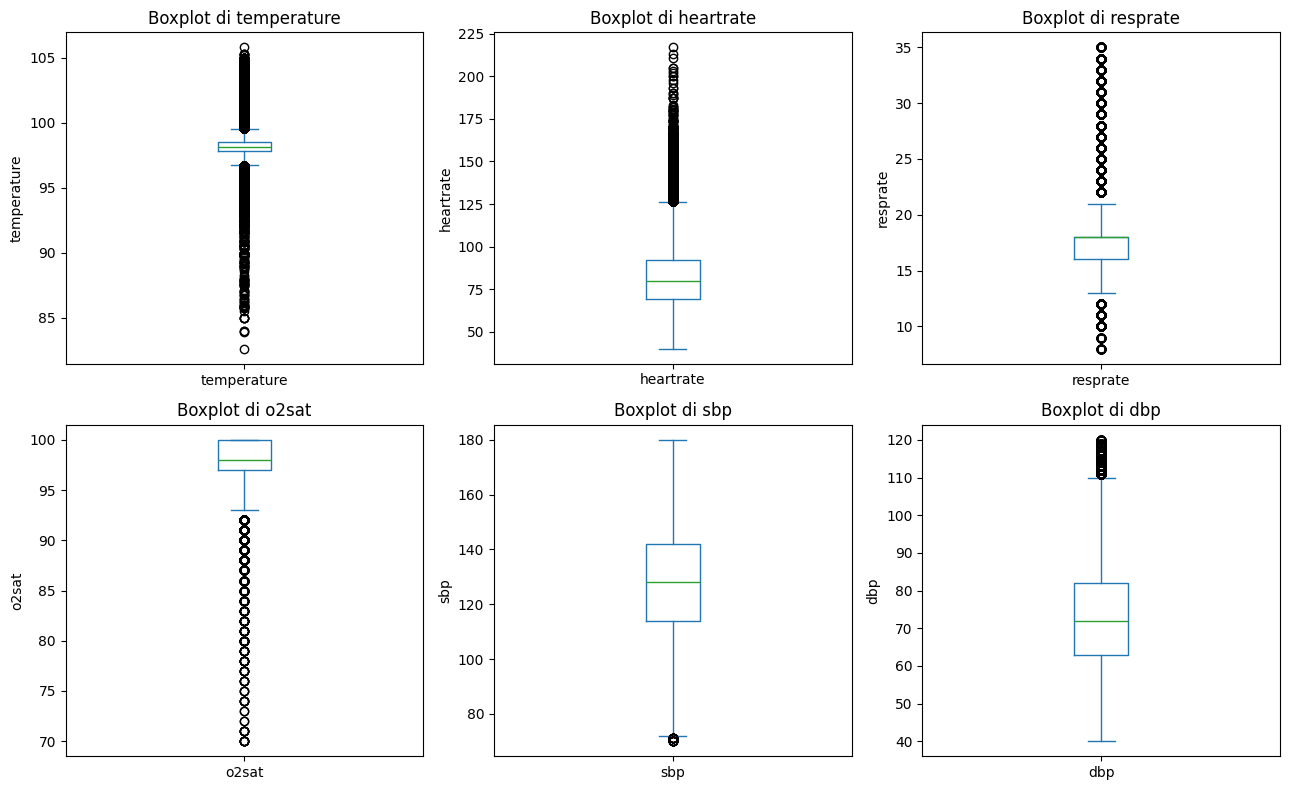

In [18]:
columns = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']

n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 4 * n_rows))
k = 2
for idx, col in enumerate(columns):
    Q1 = vital_sign_df[col].quantile(0.25)
    Q3 = vital_sign_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - k * IQR
    upper_bound = Q3 + k * IQR
    outliers = vital_sign_df[(vital_sign_df[col] < lower_bound) | (vital_sign_df[col] > upper_bound)]
    print(f"Numero di outliers in {col}: {len(outliers)}")
    row = idx // n_cols
    col_idx = idx % n_cols
    ax = axes[row, col_idx]
    vital_sign_df[col].plot(kind='box', ax=ax, title=f'Boxplot di {col}')
    ax.set_ylabel(col)

for i in range(len(columns), n_rows * n_cols):
    fig.delaxes(axes.flat[i])
plt.tight_layout()
plt.show()


## **Matrix Correlation**

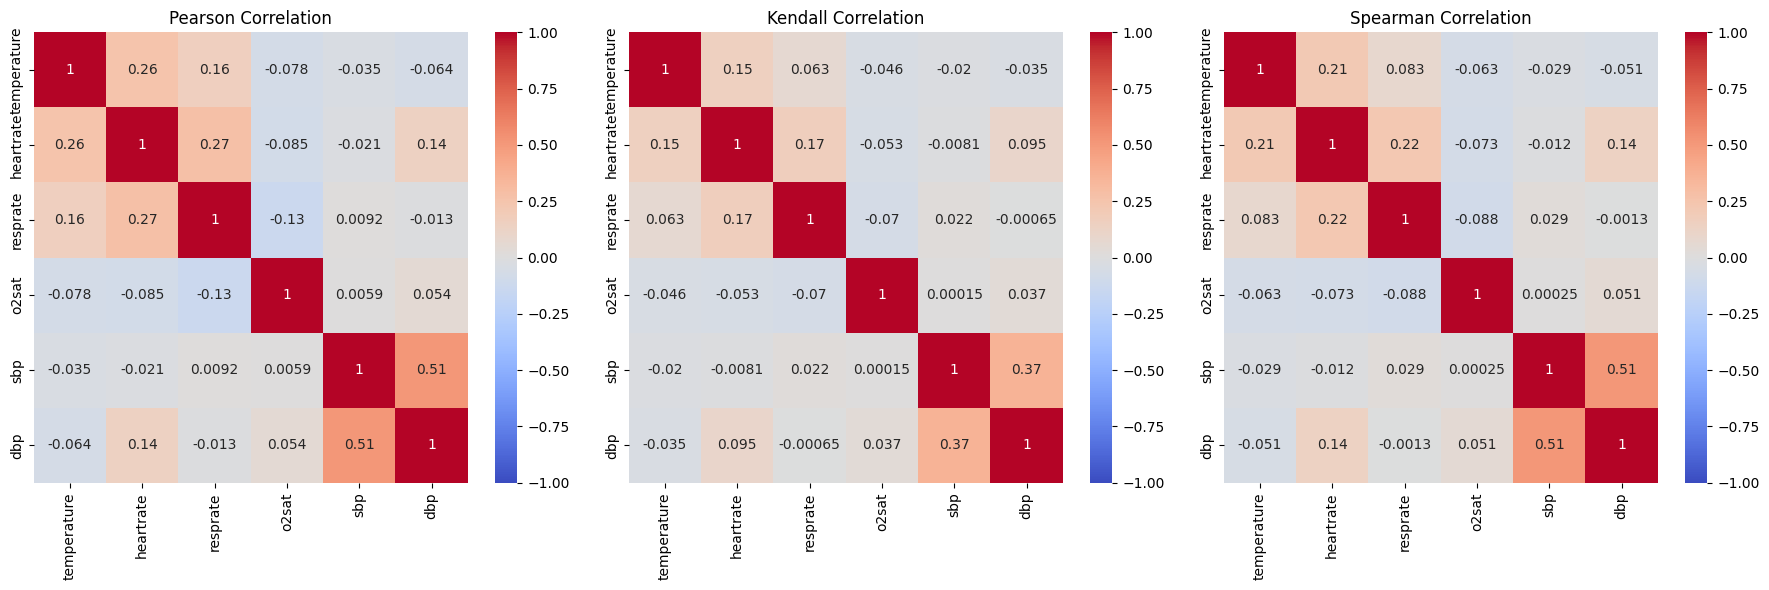

In [19]:
subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
correlation_pearson = vital_sign_df[subset_column_num].corr(method='pearson')
correlation_kendall = vital_sign_df[subset_column_num].corr(method='kendall')
correlation_spearman = vital_sign_df[subset_column_num].corr(method='spearman')

correlation_matrices = [correlation_pearson, correlation_kendall, correlation_spearman]
titles = ['Pearson Correlation', 'Kendall Correlation', 'Spearman Correlation']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for idx, (matrix, title) in enumerate(zip(correlation_matrices, titles)):
    sns.heatmap(matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[idx])
    axes[idx].set_title(title)
plt.tight_layout()
plt.show()

### Save cleaning Data

In [21]:
# Salva il DataFrame ripulito in un nuovo file CSV
vital_sign_df.to_csv('../datasets/vital_sign_cleaned.csv', index=False)